## Giai đoạn 1. Thu thập và đánh giá dữ liệu ban đầu

In [1]:
# Cài kagglehub và nạp thư viện
!pip install -q kagglehub

import os, warnings
from glob import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# Hình được lưu vào thư mục này để chèn vào báo cáo. Colab xóa nó khi session reset nên nhớ tải về.
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def show(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def fmt_p(p):
    # Mẫu lớn nên p có thể nhỏ hơn giới hạn float64 và bị làm tròn thành 0.0, in thẳng dễ hiểu nhầm
    return "< 1e-300" if p < 1e-300 else f"{p:.2e}"

In [2]:
# Tải dữ liệu từ Kaggle, nếu không được thì đọc adult.csv trong /content
def load_adult():
    try:
        import kagglehub
        folder = kagglehub.dataset_download("uciml/adult-census-income")
        # Tìm theo đuôi .csv để không phụ thuộc vào tên file
        csv_path = sorted(glob(os.path.join(folder, "**", "*.csv"), recursive=True))[0]
        print("Đã tải từ Kaggle:", csv_path)
    except Exception as e:
        print("Không tải được từ Kaggle (" + type(e).__name__ + "), thử file local")
        found = glob("/content/adult.csv") + glob("adult.csv")
        if not found:
            raise FileNotFoundError("Hãy upload adult.csv vào /content rồi chạy lại cell này")
        csv_path = found[0]
    return pd.read_csv(csv_path)

df_raw = load_adult()
# Dừng ngay nếu nạp nhầm file hoặc phiên bản khác
assert df_raw.shape == (32561, 15), f"Kích thước bất thường: {df_raw.shape}"

# Tên cột gốc có dấu chấm nên df.education.num sẽ bị hiểu là thuộc tính, đổi sang gạch dưới
df_raw.columns = df_raw.columns.str.replace(".", "_", regex=False)

df = df_raw.copy()

Using Colab cache for faster access to the 'adult-census-income' dataset.
Đã tải từ Kaggle: /kaggle/input/adult-census-income/adult.csv


In [3]:
# Cấu trúc và kiểu dữ liệu
print("Kích thước:", df.shape)
df.info()
display(df.head())

num_cols = df.select_dtypes(include="number").columns.tolist()
# Pandas 3 cảnh báo select_dtypes("object") sẽ không còn chọn cột chuỗi, nên loại trừ cột số
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Cột số:", num_cols)
print("Cột chữ:", cat_cols)

display(df[num_cols].describe().T)

Kích thước: (32561, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


Cột số: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Cột chữ: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [4]:
# Missing value, dữ liệu này mã hóa thiếu bằng "?"
# isna() chỉ thấy NaN thật nên phải đếm "?" riêng
print("Số ô NaN thật:", int(df.isna().sum().sum()))

q_count = df[cat_cols].apply(lambda s: s.str.strip().eq("?").sum())
q_tbl = pd.DataFrame({"so_dong": q_count, "ty_le_%": (q_count / len(df) * 100).round(2)})
display(q_tbl[q_tbl["so_dong"] > 0])

Số ô NaN thật: 0


,so_dong,ty_le_%
workclass,1836,5.64
occupation,1843,5.66
native_country,583,1.79


In [5]:
# Phân phối target và tính nhất quán giữa education với education_num
print(df["income"].str.strip().value_counts())
print(df["income"].str.strip().value_counts(normalize=True).round(4))

# Cả hai chiều đều bằng 1 nghĩa là hai cột mã hóa cùng một thông tin
print("Số mã education_num tối đa ứng với 1 education:",
      df.groupby("education")["education_num"].nunique().max())
print("Số education tối đa ứng với 1 mã education_num:",
      df.groupby("education_num")["education"].nunique().max())

income
<=50K    24720
>50K      7841
Name: count, dtype: int64
income
<=50K    0.7592
>50K     0.2408
Name: proportion, dtype: float64
Số mã education_num tối đa ứng với 1 education: 1
Số education tối đa ứng với 1 mã education_num: 1


## Giai đoạn 2. Tiền xử lý và làm sạch dữ liệu

### 2.1 Giá trị thiếu

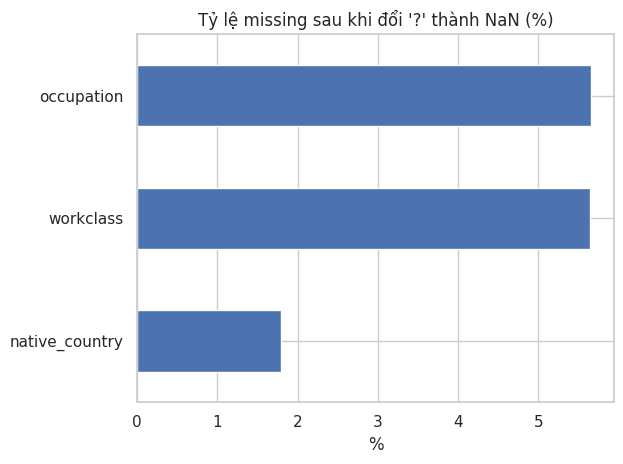

native_country    1.79
workclass         5.64
occupation        5.66
dtype: float64


In [6]:
# Đổi "?" thành NaN và tạo target nhị phân
for c in cat_cols:
    df[c] = df[c].str.strip().replace("?", np.nan)

df["income_bin"] = (df["income"] == ">50K").astype(int)

miss_pct = df.isna().mean().mul(100)
miss_pct = miss_pct[miss_pct > 0].sort_values()
miss_pct.plot.barh(title="Tỷ lệ missing sau khi đổi '?' thành NaN (%)")
plt.xlabel("%")
show("01_missing")
print(miss_pct.round(2))

In [7]:
# Kiểm tra cơ chế thiếu
# workclass và occupation thiếu gần như cùng các dòng
print(pd.crosstab(df["workclass"].isna(), df["occupation"].isna(),
                  rownames=["workclass thiếu"], colnames=["occupation thiếu"]))

# Các dòng chỉ thiếu occupation
print(df.loc[df["occupation"].isna() & df["workclass"].notna(), "workclass"].value_counts())

# Xét từng cột riêng. Gộp thành một cờ "có thiếu" sẽ che mất việc native_country
# hành xử khác hai cột còn lại.
rows = []
for c in ["workclass", "occupation", "native_country"]:
    m = df[c].isna()
    rows.append({"cot": c, "n_thieu": int(m.sum()),
                 "ty_le_>50K_khi_thieu_%": round(df.loc[m, "income_bin"].mean() * 100, 1),
                 "ty_le_>50K_khi_du_%": round(df.loc[~m, "income_bin"].mean() * 100, 1)})
display(pd.DataFrame(rows))

occupation thiếu  False  True 
workclass thiếu               
False             30718      7
True                  0   1836
workclass
Never-worked    7
Name: count, dtype: int64


,cot,n_thieu,ty_le_>50K_khi_thieu_%,ty_le_>50K_khi_du_%
0,workclass,1836,10.4,24.9
1,occupation,1843,10.4,24.9
2,native_country,583,25.0,24.1


In [8]:
# Điền missing bằng nhãn "Unknown"
# Cả ba cột đều là biến phân loại. Với workclass và occupation, thiếu đi cùng tỷ lệ thu nhập
# khác hẳn, nên điền mode sẽ gán nghề phổ biến cho người không khai báo. Nhãn riêng giữ được
# số dòng và cả thông tin "không khai báo". native_country làm cùng cách cho nhất quán.
for c in ["workclass", "occupation", "native_country"]:
    df[c] = df[c].fillna("Unknown")

assert df.isna().sum().sum() == 0
print("Còn missing:", int(df.isna().sum().sum()))

Còn missing: 0


### 2.2 Dòng trùng lặp

In [9]:
# Tìm dòng trùng lặp
n_dup = df.duplicated().sum()
print("Số dòng bị đánh dấu trùng (giữ bản đầu):", n_dup)
print("Tổng số dòng thuộc các nhóm trùng:", df.duplicated(keep=False).sum())
display(df[df.duplicated(keep=False)].sort_values(["age", "fnlwgt"]).head(6))

# Các bản trùng có nhãn income mâu thuẫn nhau không
feat_cols = [c for c in df.columns if c not in ("income", "income_bin")]
grp = df[df.duplicated(keep=False)].groupby(feat_cols, dropna=False)["income"].nunique()
print("Số nhóm trùng có nhãn income khác nhau:", int((grp > 1).sum()))

Số dòng bị đánh dấu trùng (giữ bản đầu): 24
Tổng số dòng thuộc các nhóm trùng: 47


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,income_bin
19622,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
20507,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
10307,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K,0
22783,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K,0
17456,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K,0
22934,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K,0


Số nhóm trùng có nhãn income khác nhau: 0


In [10]:
# Loại dòng trùng
# Không có cột ID nên không chứng minh chắc chắn đây là bản ghi lặp. Loại vì chỉ 24 dòng
# và nhãn nhất quán, rồi so tỷ lệ >50K trước sau để xem ảnh hưởng.
rate_before = df["income_bin"].mean() * 100
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"{n_before} -> {len(df)} dòng | tỷ lệ >50K: {rate_before:.3f}% -> {df['income_bin'].mean()*100:.3f}%")

32561 -> 32537 dòng | tỷ lệ >50K: 24.081% -> 24.093%


### 2.3 Ngoại lệ

In [11]:
# Phát hiện outlier bằng IQR
def iqr_report(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    n = ((s < lo) | (s > hi)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "can_duoi": lo, "can_tren": hi,
                      "so_outlier": n, "ty_le_%": round(n / len(s) * 100, 2),
                      "min": s.min(), "max": s.max()})

# fnlwgt chỉ xét ở đây để báo cáo, các bước sau không dùng vì nó là trọng số lấy mẫu
num_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
display(df[num_cols].apply(iqr_report).T)

,Q1,Q3,can_duoi,can_tren,so_outlier,ty_le_%,min,max
age,28.0,48.0,-2.0,78.0,142.0,0.44,17.0,90.0
fnlwgt,117827.0,236993.0,-60922.0,415742.0,993.0,3.05,12285.0,1484705.0
education_num,9.0,12.0,4.5,16.5,1193.0,3.67,1.0,16.0
capital_gain,0.0,0.0,0.0,0.0,2712.0,8.34,0.0,99999.0
capital_loss,0.0,0.0,0.0,0.0,1519.0,4.67,0.0,4356.0
hours_per_week,40.0,45.0,32.5,52.5,9002.0,27.67,1.0,99.0


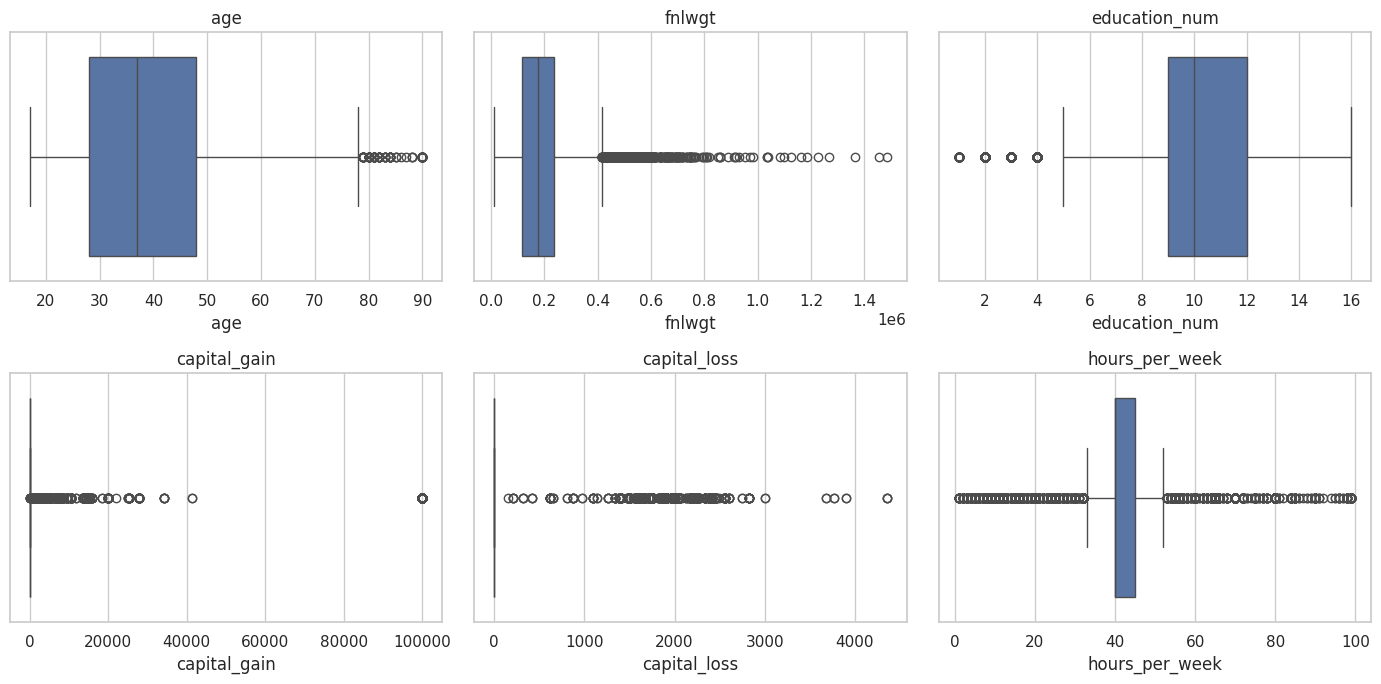

In [12]:
# Boxplot các cột số
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
show("02_boxplot_numeric")

In [13]:
# capital_gain và capital_loss
# Hơn 90% giá trị là 0 nên Q1 = Q3 = 0 và IQR = 0, mọi giá trị khác 0 đều bị gắn outlier.
# Kết quả IQR ở hai cột này không có ý nghĩa, nên mô tả bằng tỷ lệ khác 0 và đuôi phân phối.
for c in ["capital_gain", "capital_loss"]:
    nz = df[c] > 0
    print(f"{c}: khác 0 = {nz.mean()*100:.2f}% (n = {nz.sum()}) | median(khác 0) = {df.loc[nz, c].median():,.0f}"
          f" | max = {df[c].max():,}")

# 99999 lặp lại nhiều bất thường, giống giá trị bị chặn trên hơn là số đo thật
print("\nSố dòng capital_gain = 99999:", (df["capital_gain"] == 99999).sum())
print("Nhãn income của nhóm này:", df.loc[df["capital_gain"] == 99999, "income"].value_counts().to_dict())
print("\nCác giá trị capital_gain xuất hiện nhiều nhất:")
print(df["capital_gain"].value_counts().head(5))
print("\nDòng có đồng thời gain > 0 và loss > 0:", ((df["capital_gain"] > 0) & (df["capital_loss"] > 0)).sum())

capital_gain: khác 0 = 8.34% (n = 2712) | median(khác 0) = 7,298 | max = 99,999
capital_loss: khác 0 = 4.67% (n = 1519) | median(khác 0) = 1,887 | max = 4,356

Số dòng capital_gain = 99999: 159
Nhãn income của nhóm này: {'>50K': 159}

Các giá trị capital_gain xuất hiện nhiều nhất:
capital_gain
0        29825
15024      347
7688       284
7298       246
99999      159
Name: count, dtype: int64

Dòng có đồng thời gain > 0 và loss > 0: 0


In [14]:
# hours_per_week và age
# Gần một nửa số dòng nằm đúng ở 40 giờ nên khoảng Q1 đến Q3 chỉ rộng 5 giờ, IQR vì vậy
# gắn outlier cho rất nhiều dòng dù các giá trị này không phải lỗi.
print("Tỷ lệ hours = 40: %.1f%%" % ((df["hours_per_week"] == 40).mean() * 100))
print("hours >= 80:", (df["hours_per_week"] >= 80).sum(), "| hours == 99:", (df["hours_per_week"] == 99).sum())
print("age >= 80:", (df["age"] >= 80).sum(), "| age == 90:", (df["age"] == 90).sum(), "| tuổi nhỏ nhất:", df["age"].min())

# Nhóm cực trị có hành xử khác phần còn lại không, để quyết định giữ hay bỏ
print("\nTỷ lệ >50K: toàn mẫu %.1f%% | hours >= 80: %.1f%% | age >= 80: %.1f%%" % (
    df["income_bin"].mean() * 100,
    df.loc[df["hours_per_week"] >= 80, "income_bin"].mean() * 100,
    df.loc[df["age"] >= 80, "income_bin"].mean() * 100))

Tỷ lệ hours = 40: 46.7%
hours >= 80: 341 | hours == 99: 85
age >= 80: 120 | age == 90: 42 | tuổi nhỏ nhất: 17

Tỷ lệ >50K: toàn mẫu 24.1% | hours >= 80: 35.2% | age >= 80: 13.3%


### 2.4 Biến đổi và mã hóa

In [15]:
# Tạo biến nhóm và biến đổi log
# Tuổi nhỏ nhất là 17 nên khoảng đầu bắt đầu từ 16
df["age_group"] = pd.cut(df["age"], bins=[16, 24, 34, 44, 54, 64, 100],
                         labels=["17-24", "25-34", "35-44", "45-54", "55-64", "65+"])
# Mốc 40 giờ được tách riêng vì là giá trị phổ biến nhất
df["hours_group"] = pd.cut(df["hours_per_week"], bins=[0, 34, 40, 50, 100],
                           labels=["<=34", "35-40", "41-50", ">50"])

# log1p thay vì log vì hai cột có rất nhiều giá trị 0
df["log_cap_gain"] = np.log1p(df["capital_gain"])
df["log_cap_loss"] = np.log1p(df["capital_loss"])

# Mỹ chiếm khoảng 90% còn các nước khác mỗi nước rất ít dòng, gộp lại để bảng và biểu đồ không loãng
df["native_group"] = np.select(
    [df["native_country"] == "United-States", df["native_country"] == "Unknown"],
    ["US", "Unknown"], default="Non-US")
print(df["native_group"].value_counts())

native_group
US         29153
Non-US      2802
Unknown      582
Name: count, dtype: int64


,skew_goc,skew_log1p
capital_gain,11.95,3.09
capital_loss,4.59,4.31


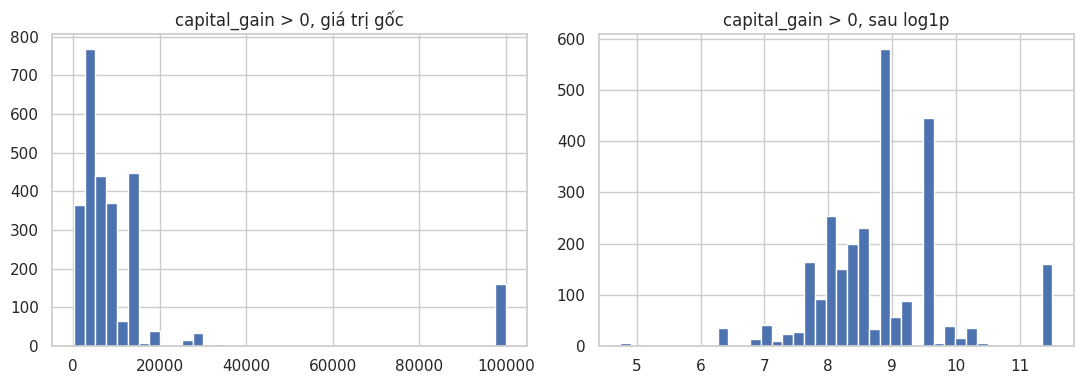

Độ lệch của nhóm > 0: gốc 3.41 -> log1p 0.56


In [16]:
# Độ lệch trước và sau log1p
skew_tbl = pd.DataFrame({
    "skew_goc": [df["capital_gain"].skew(), df["capital_loss"].skew()],
    "skew_log1p": [df["log_cap_gain"].skew(), df["log_cap_loss"].skew()],
}, index=["capital_gain", "capital_loss"]).round(2)
display(skew_tbl)

# Vẽ riêng các dòng khác 0, vì phần giá trị 0 chiếm đa số sẽ che hết phần còn lại
pos = df[df["capital_gain"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(pos["capital_gain"], bins=40)
axes[0].set_title("capital_gain > 0, giá trị gốc")
axes[1].hist(pos["log_cap_gain"], bins=40)
axes[1].set_title("capital_gain > 0, sau log1p")
show("03_capital_gain_log")
print("Độ lệch của nhóm > 0: gốc %.2f -> log1p %.2f" % (pos["capital_gain"].skew(), pos["log_cap_gain"].skew()))

## Giai đoạn 3. Phân tích và trực quan hóa

In [17]:
# Hàm dùng chung cho phần kiểm định
def cramers_v(x, y):
    # V nằm trong [0, 1], dùng để so độ mạnh liên hệ giữa các biến phân loại
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return chi2, p, v

def rate_by(col):
    # Luôn kèm n vì nhóm nhỏ cho tỷ lệ không ổn định
    g = df.groupby(col, observed=True)["income_bin"]
    return pd.DataFrame({"ty_le_%": g.mean().mul(100).round(1), "n": g.size()})

print("Tỷ lệ >50K toàn mẫu: %.2f%%" % (df["income_bin"].mean() * 100))

Tỷ lệ >50K toàn mẫu: 24.09%


### H1. Học vấn càng cao thì tỷ lệ thu nhập trên 50K càng cao

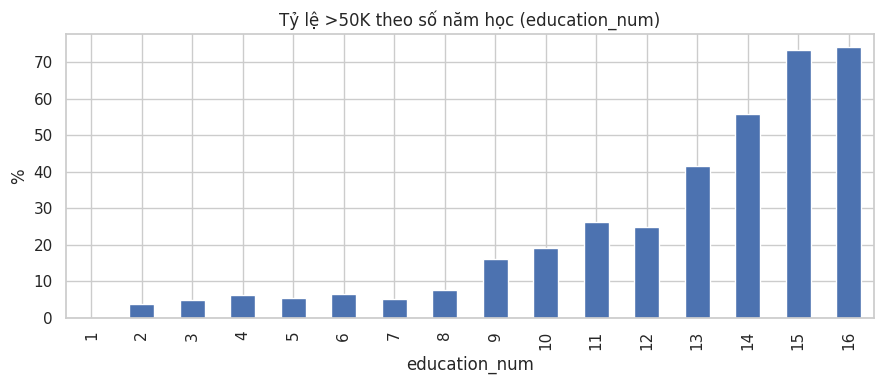

Spearman rho = 0.330, p < 1e-300


education_num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
ty_le_%,0.0,3.6,4.8,6.2,5.3,6.6,5.1,7.6,16.0,19.0,26.1,24.8,41.5,55.7,73.4,74.1
n,50.0,166.0,332.0,645.0,514.0,933.0,1175.0,433.0,10494.0,7282.0,1382.0,1067.0,5353.0,1722.0,576.0,413.0


In [18]:
# H1 theo số năm học
t = rate_by("education_num")
t["ty_le_%"].plot.bar(figsize=(9, 4), title="Tỷ lệ >50K theo số năm học (education_num)")
plt.ylabel("%")
show("04_h1_education")

rho, p = stats.spearmanr(df["education_num"], df["income_bin"])
print(f"Spearman rho = {rho:.3f}, p {fmt_p(p)}")
display(t.T)

### H2. Tỷ lệ thu nhập cao tăng theo tuổi rồi giảm ở nhóm lớn tuổi

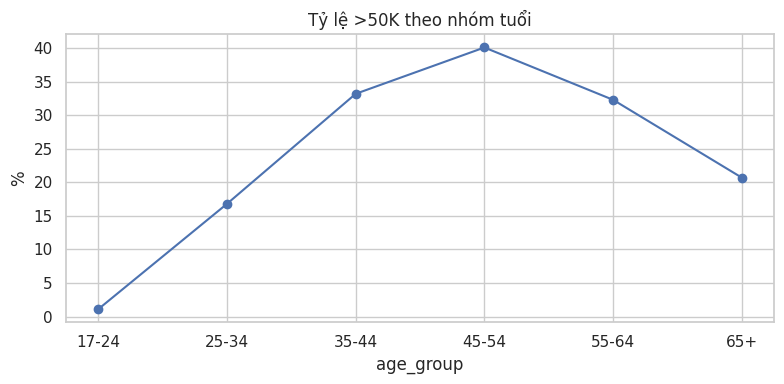

chi2 = 3168.5, p < 1e-300, Cramér's V = 0.312


age_group,17-24,25-34,35-44,45-54,55-64,65+
ty_le_%,1.1,16.8,33.2,40.1,32.3,20.7
n,5562.0,8473.0,8146.0,5849.0,3172.0,1335.0


In [19]:
# H2 theo nhóm tuổi
t = rate_by("age_group")
t["ty_le_%"].plot(marker="o", figsize=(8, 4), title="Tỷ lệ >50K theo nhóm tuổi")
plt.ylabel("%")
show("05_h2_age")

chi2, p, v = cramers_v(df["age_group"], df["income_bin"])
print(f"chi2 = {chi2:.1f}, p {fmt_p(p)}, Cramér's V = {v:.3f}")
display(t.T)

### H3. Người làm nhiều giờ hơn có thu nhập cao hơn

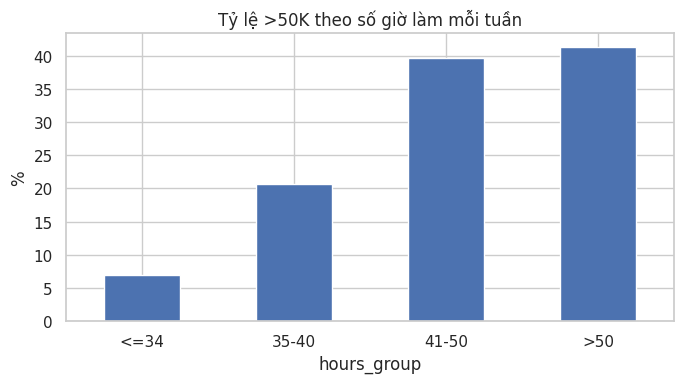

hours_group,<=34,35-40,41-50,>50
ty_le_%,6.9,20.7,39.6,41.3
n,5578.0,17383.0,5934.0,3642.0


median: >50K = 40.0, <=50K = 40.0 | mean: >50K = 45.47, <=50K = 38.84
Mann-Whitney p < 1e-300


In [20]:
# H3 theo số giờ làm
t = rate_by("hours_group")
t["ty_le_%"].plot.bar(figsize=(7, 4), title="Tỷ lệ >50K theo số giờ làm mỗi tuần")
plt.ylabel("%"); plt.xticks(rotation=0)
show("06_h3_hours")
display(t.T)

# Mann-Whitney vì hours_per_week dồn ở 40, không phân phối chuẩn
a = df.loc[df["income_bin"] == 1, "hours_per_week"]
b = df.loc[df["income_bin"] == 0, "hours_per_week"]
u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
# Median của hai nhóm đều là 40 nên phải xem thêm trung bình
print(f"median: >50K = {a.median()}, <=50K = {b.median()} | mean: >50K = {a.mean():.2f}, <=50K = {b.mean():.2f}")
print(f"Mann-Whitney p {fmt_p(p)}")

### H4. Chênh lệch thu nhập theo giới tính còn lại gì sau khi tách theo hôn nhân và giờ làm

In [21]:
# H4 giới tính, số liệu thô
print(rate_by("sex"))
chi2, p, v = cramers_v(df["sex"], df["income_bin"])
print(f"Giới tính: Cramér's V = {v:.3f}, p {fmt_p(p)}")

        ty_le_%      n
sex                   
Female     11.0  10762
Male       30.6  21775
Giới tính: Cramér's V = 0.216, p < 1e-300


Theo hôn nhân x giới tính:
                    mean   size
is_married sex                 
Khác       Female  0.047   9105
           Male    0.086   8462
Đã kết hôn Female  0.455   1657
           Male    0.446  13313

Theo giờ làm x giới tính:
sex          Female   Male
hours_group               
<=34          0.062  0.077
35-40         0.103  0.263
41-50         0.216  0.441
>50           0.204  0.451


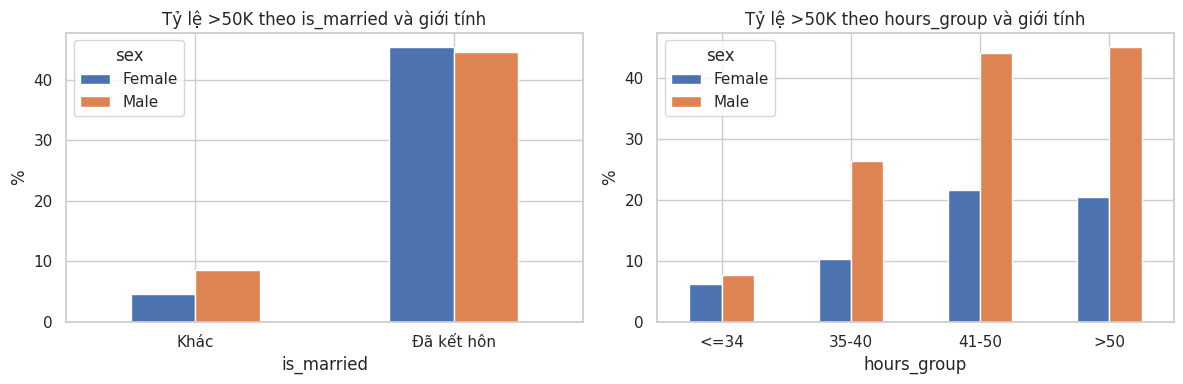

In [22]:
# H4 tách theo hôn nhân và giờ làm để xem chênh lệch thô có còn không
df["is_married"] = np.where(df["marital_status"] == "Married-civ-spouse", "Đã kết hôn", "Khác")
print("Theo hôn nhân x giới tính:")
print(df.groupby(["is_married", "sex"])["income_bin"].agg(["mean", "size"]).round(3))
print("\nTheo giờ làm x giới tính:")
print(df.groupby(["hours_group", "sex"], observed=True)["income_bin"].mean().unstack().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, ["is_married", "hours_group"]):
    (df.groupby([g, "sex"], observed=True)["income_bin"].mean().mul(100)
       .unstack().plot.bar(ax=ax, title=f"Tỷ lệ >50K theo {g} và giới tính"))
    ax.set_ylabel("%"); ax.tick_params(axis="x", rotation=0)
show("07_h4_sex")

### H5. Tình trạng hôn nhân liên hệ mạnh với thu nhập

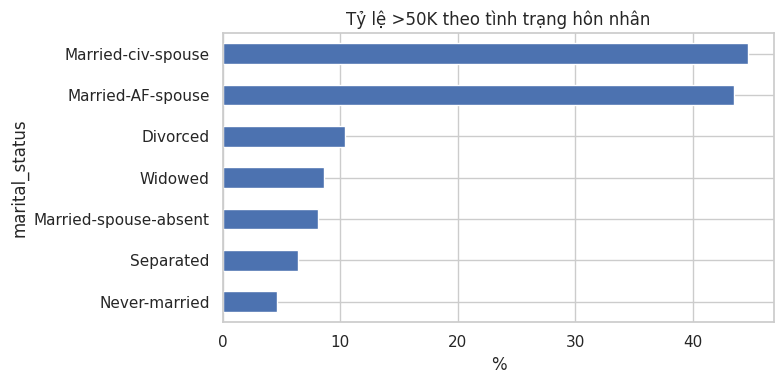

,ty_le_%,n
marital_status,,
Never-married,4.6,10667
Separated,6.4,1025
Married-spouse-absent,8.1,418
Widowed,8.6,993
Divorced,10.4,4441
Married-AF-spouse,43.5,23
Married-civ-spouse,44.7,14970


marital_status
Never-married            25.0
Married-AF-spouse        30.0
Separated                38.0
Married-spouse-absent    40.0
Married-civ-spouse       42.0
Divorced                 42.0
Widowed                  60.0
Name: age, dtype: float64
is_married   Khác  Đã kết hôn
age_group                    
17-24       0.005       0.070
25-34       0.050       0.336
35-44       0.107       0.503
45-54       0.144       0.560
55-64       0.113       0.445
65+         0.072       0.313


In [23]:
# H5 theo tình trạng hôn nhân
t = rate_by("marital_status").sort_values("ty_le_%")
t["ty_le_%"].plot.barh(figsize=(8, 4), title="Tỷ lệ >50K theo tình trạng hôn nhân")
plt.xlabel("%")
show("08_h5_marital")
display(t)

# Hôn nhân đi cùng tuổi nên xem tuổi trung vị từng nhóm, rồi so sánh ngay trong từng nhóm tuổi
print(df.groupby("marital_status")["age"].median().sort_values())
print(df.groupby(["age_group", "is_married"], observed=True)["income_bin"].mean().unstack().round(3))

### Độ mạnh liên hệ giữa các biến và thu nhập

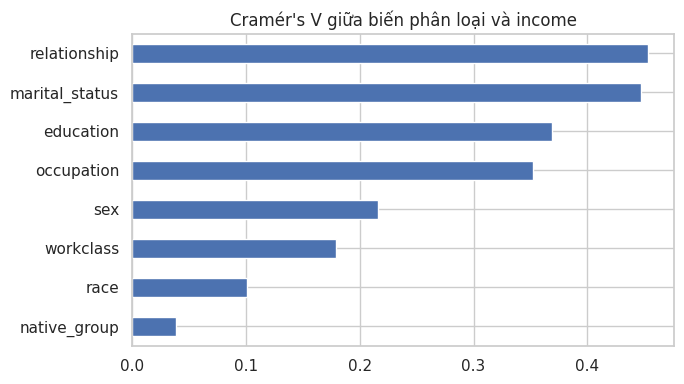

native_group      0.039
race              0.101
workclass         0.179
sex               0.216
occupation        0.352
education         0.369
marital_status    0.447
relationship      0.454
dtype: float64


In [24]:
# So sánh độ mạnh liên hệ bằng Cramér's V
cat_feats = ["workclass", "education", "marital_status", "occupation",
             "relationship", "race", "sex", "native_group"]
v_all = pd.Series({c: cramers_v(df[c], df["income_bin"])[2] for c in cat_feats}).sort_values()
v_all.plot.barh(figsize=(7, 4), title="Cramér's V giữa biến phân loại và income")
show("09_cramers_v")
print(v_all.round(3))

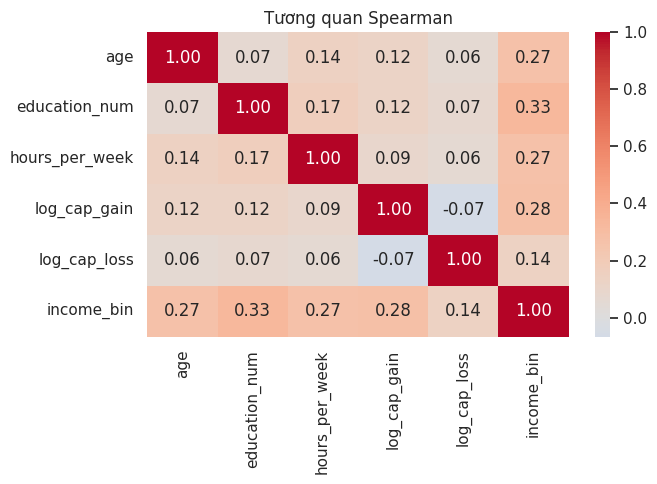

In [25]:
# Heatmap tương quan
# Spearman vì biến lệch và nhiều giá trị 0. Nó dựa trên thứ hạng nên dùng cột capital gốc
# hay cột log đều cho đúng cùng kết quả.
corr_cols = ["age", "education_num", "hours_per_week", "log_cap_gain", "log_cap_loss", "income_bin"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Tương quan Spearman")
show("10_heatmap")

## Giai đoạn 4. Đánh giá tác động và khuyến nghị

Phần này được trình bày trong báo cáo, dựa trên kết quả của Giai đoạn 3.